#### Classification – High-Demand Session Prediction
Here I'll classify each session as High Demand (Demand ≥ train median) or Normal Demand, compare multiple models and explain the best one.

#### Step-0: Setup

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

import shap
from lime.lime_tabular import LimeTabularExplainer

#### Step-1: Load and time-based split

In [2]:
# Same split as regression: first 80% of sessions for train, last 20% for test
df= pd.read_csv("../data/cleaned/model_ready.csv", parse_dates=['StartDatetime'])
split= int(len(df)*0.8)
train= df.iloc[:split].copy()
test= df.iloc[split:].copy()
train.shape, test.shape

((57670, 14), (14418, 14))

#### Step-2: Creating the target

In [3]:
# Median from TRAIN set only, so test data does not leak.
median_demand= train['Demand'].median()
median_demand

np.float64(14.35)

In [4]:
# 1 = High Demand (Demand >= median), 0 = Normal Demand
train['HighDemand']= (train['Demand']>=median_demand).astype(int)
test['HighDemand']= (test['Demand']>=median_demand).astype(int)

#### Step-3: Class balance check

In [5]:
# Class share in train
train['HighDemand'].value_counts(normalize=True)

HighDemand
1    0.500225
0    0.499775
Name: proportion, dtype: float64

In [6]:
# Class share in test
test['HighDemand'].value_counts(normalize=True)
# Obervation: Both classes are almost equal in train and test

HighDemand
0    0.512692
1    0.487308
Name: proportion, dtype: float64

#### Step-4: Features and target

In [7]:
# Same features as regression
num_cols= ['ChargerCompany', 'ChargerType', 'Hour', 'Weekday', 'IsWeekend', 'IsGuest','UserPastSessions', 
           'UserPastAvgDemand', 'ChargerPastSessions', 'ChargerPastAvgDemand']
cat_cols= ['Location']

X_train= train[num_cols+cat_cols]
y_train= train['HighDemand']
X_test= test[num_cols+cat_cols]
y_test= test['HighDemand']

#### Step-5: Preprocessing

In [8]:
# Median imputing, scaling for numbers, one-hot for Location
num_pipe= Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
preprocess= ColumnTransformer([('num', num_pipe, num_cols), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

#### Step-6: Model comparison with time series split CV

In [9]:
# Splitting into time series split for the cross validation
tscv= TimeSeriesSplit(n_splits=3)

# Function to take the model and train and test based on cross validation
def cv_score(name, model):
    pipe= Pipeline([('preprocess', preprocess), ('model', model)])
    scores= cross_validate(pipe, X_train, y_train, cv=tscv, scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
                           return_train_score=True)
    print(name,
          '| Train Acc:', round(scores['train_accuracy'].mean(), 3),
          '| Val Acc:', round(scores['test_accuracy'].mean(), 3),
          '| Val Precision:', round(scores['test_precision'].mean(), 3),
          '| Val Recall:', round(scores['test_recall'].mean(), 3),
          '| Val F1:', round(scores['test_f1'].mean(), 3),
          '| Train AUC:', round(scores['train_roc_auc'].mean(), 3),
          '| Val AUC:', round(scores['test_roc_auc'].mean(), 3))

In [10]:
# Baseline: always predicts the most common class
cv_score('Dummy', DummyClassifier(strategy='most_frequent'))

Dummy | Train Acc: 0.504 | Val Acc: 0.498 | Val Precision: 0.498 | Val Recall: 1.0 | Val F1: 0.665 | Train AUC: 0.5 | Val AUC: 0.5


In [11]:
# Logistic Regression
cv_score('Logistic Regression', LogisticRegression(max_iter=1000))

Logistic Regression | Train Acc: 0.692 | Val Acc: 0.698 | Val Precision: 0.686 | Val Recall: 0.726 | Val F1: 0.705 | Train AUC: 0.764 | Val AUC: 0.78


In [12]:
# Decision Tree
cv_score('Decision Tree', DecisionTreeClassifier(max_depth=8, random_state=42))

Decision Tree | Train Acc: 0.737 | Val Acc: 0.714 | Val Precision: 0.701 | Val Recall: 0.744 | Val F1: 0.722 | Train AUC: 0.819 | Val AUC: 0.777


In [13]:
# Random Forest
cv_score('Random Forest', RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))

Random Forest | Train Acc: 0.792 | Val Acc: 0.736 | Val Precision: 0.722 | Val Recall: 0.764 | Val F1: 0.742 | Train AUC: 0.883 | Val AUC: 0.817


In [14]:
# KNN
cv_score('KNN', KNeighborsClassifier(n_neighbors=15))

KNN | Train Acc: 0.756 | Val Acc: 0.713 | Val Precision: 0.71 | Val Recall: 0.719 | Val F1: 0.714 | Train AUC: 0.843 | Val AUC: 0.789


In [15]:
# Linear SVM
cv_score('SVM (Linear)', LinearSVC(random_state=42))

SVM (Linear) | Train Acc: 0.691 | Val Acc: 0.696 | Val Precision: 0.686 | Val Recall: 0.72 | Val F1: 0.702 | Train AUC: 0.762 | Val AUC: 0.778


In [16]:
# XGBoost
cv_score('XGBoost', XGBClassifier(random_state=42))

XGBoost | Train Acc: 0.809 | Val Acc: 0.725 | Val Precision: 0.714 | Val Recall: 0.749 | Val F1: 0.731 | Train AUC: 0.901 | Val AUC: 0.805


In [17]:
# LightGBM
cv_score('LightGBM', LGBMClassifier(random_state=42, verbose=-1))

LightGBM | Train Acc: 0.764 | Val Acc: 0.731 | Val Precision: 0.713 | Val Recall: 0.771 | Val F1: 0.741 | Train AUC: 0.853 | Val AUC: 0.814


#### Observations:
1. Random Forest and LightGBM are the top two and almost equal. 
2. XGBoost and Random Forest show the biggest train–validation gap (overfitting).
3. Linear models (LR, SVM) are weakest, so the relationships are non-linear.

#### Step-7: SMOTE check

In [18]:
# SMOTE inside the pipeline so it runs only on training folds
smote_pipe= ImbPipeline([('preprocess', preprocess), ('smote', SMOTE(random_state=42)),
                         ('model', LGBMClassifier(random_state=42, verbose=-1))])
smote_scores= cross_validate(smote_pipe, X_train, y_train, cv=tscv, scoring=['accuracy', 'f1', 'roc_auc'])
print('Val Accuracy:', round(smote_scores['test_accuracy'].mean(), 3))
print('Val F1:', round(smote_scores['test_f1'].mean(), 3))
print('Val ROC-AUC:', round(smote_scores['test_roc_auc'].mean(), 3))

Val Accuracy: 0.733
Val F1: 0.74
Val ROC-AUC: 0.813


#### Observation: 
1. SMOTE gives no improvement because the classes are already balanced, so the final models are trained without resampling.

#### Step-8: Tuning the top 2 models

In [19]:
# Random Forest tuning (ROC-AUC: checks ranking of High vs Normal at all thresholds)
rf_params= {'model__n_estimators': [100, 200, 300],
            'model__max_depth': [8, 12, 16, None],
            'model__min_samples_leaf': [1, 5, 20, 50],
            'model__max_features': ['sqrt', 0.5]}
rf_pipe= Pipeline([('preprocess', preprocess), ('model', RandomForestClassifier(random_state=42, n_jobs=-1))])
rf_search= RandomizedSearchCV(rf_pipe, rf_params, n_iter=10, cv=tscv, scoring='roc_auc', random_state=42)
rf_search.fit(X_train, y_train)
rf_search.best_params_, round(rf_search.best_score_, 3)

({'model__n_estimators': 300,
  'model__min_samples_leaf': 5,
  'model__max_features': 'sqrt',
  'model__max_depth': None},
 np.float64(0.819))

In [20]:
# LightGBM tuning
lgbm_params= {'model__n_estimators': [100, 200, 300, 500],
              'model__learning_rate': [0.01, 0.05, 0.1],
              'model__num_leaves': [15, 31, 63],
              'model__max_depth': [-1, 5, 10],
              'model__min_child_samples': [20, 50, 100]}
lgbm_pipe= Pipeline([('preprocess', preprocess), ('model', LGBMClassifier(random_state=42, verbose=-1))])
lgbm_search= RandomizedSearchCV(lgbm_pipe, lgbm_params, n_iter=10, cv=tscv, scoring='roc_auc', random_state=42)
lgbm_search.fit(X_train, y_train)
lgbm_search.best_params_, round(lgbm_search.best_score_, 3)

({'model__num_leaves': 63,
  'model__n_estimators': 100,
  'model__min_child_samples': 50,
  'model__max_depth': 5,
  'model__learning_rate': 0.1},
 np.float64(0.817))

#### Observations:
1. Both tuned models score almost the same. LightGBM is chosen as the final model.

#### Step-9: Test evaluation

In [21]:
# Final model on unseen test data (used once)
best_model= lgbm_search.best_estimator_
y_pred= best_model.predict(X_test)
y_prob= best_model.predict_proba(X_test)[:, 1]

print('Accuracy:', round(accuracy_score(y_test, y_pred), 3))
print('Precision:', round(precision_score(y_test, y_pred), 3))
print('Recall:', round(recall_score(y_test, y_pred), 3))
print('F1:', round(f1_score(y_test, y_pred), 3))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 3))

Accuracy: 0.726
Precision: 0.692
Recall: 0.789
F1: 0.737
ROC-AUC: 0.806


In [22]:
# Baseline: predicting the most common train class for every test session
(y_test==y_train.mode()[0]).mean()

np.float64(0.4873075322513525)

In [23]:
# Per class report
print(classification_report(y_test, y_pred, target_names=['Normal', 'High']))

              precision    recall  f1-score   support

      Normal       0.77      0.67      0.71      7392
        High       0.69      0.79      0.74      7026

    accuracy                           0.73     14418
   macro avg       0.73      0.73      0.73     14418
weighted avg       0.73      0.73      0.73     14418



#### Step-10: Confusion matrix

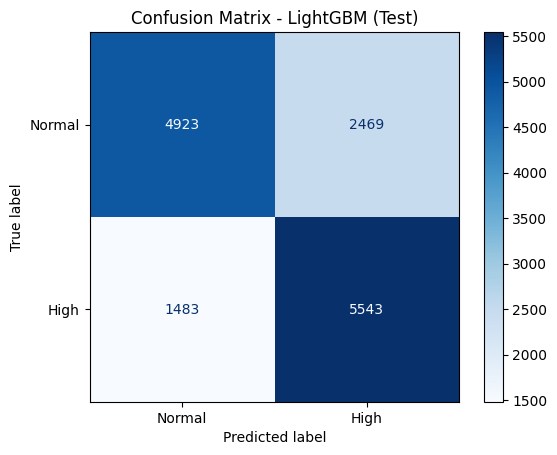

In [24]:
# Correct vs wrong predictions per class
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Normal', 'High'], cmap='Blues')
plt.title('Confusion Matrix - LightGBM (Test)')
plt.show()

#### Step-11: ROC curve

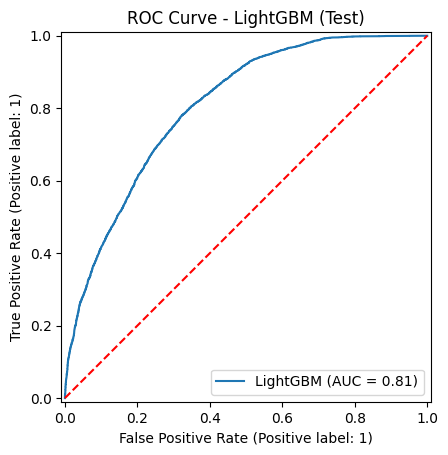

In [25]:
# Trade-off between true positive and false positive rate
RocCurveDisplay.from_predictions(y_test, y_prob, name='LightGBM')
plt.plot([0, 1], [0, 1], 'r--')
plt.title('ROC Curve - LightGBM (Test)')
plt.show()

#### Observations: 
1. The model catches most high-demand sessions (higher recall) but also labels some normal sessions as high (more false positives than false negatives).

#### Step-12: Feature importance

In [26]:
# Gain importance from the LightGBM model
lgbm_model= best_model.named_steps['model']
feature_names= best_model.named_steps['preprocess'].get_feature_names_out()
importance= pd.DataFrame({'Feature': feature_names,
                          'Importance': lgbm_model.booster_.feature_importance(importance_type='gain')})
importance['Importance %']= (importance['Importance']/importance['Importance'].sum()*100).round(2)
importance= importance.sort_values('Importance', ascending=False)
importance.head(10)

,Feature,Importance,Importance %
7,num__UserPastAvgDemand,70484.560754,58.72
2,num__Hour,16760.318188,13.96
9,num__ChargerPastAvgDemand,16069.910214,13.39
6,num__UserPastSessions,4459.818908,3.72
1,num__ChargerType,3872.718346,3.23
8,num__ChargerPastSessions,2721.110690,2.27
17,cat__Location_market,945.523690,0.79
0,num__ChargerCompany,862.582874,0.72
21,cat__Location_resort,830.506804,0.69
11,cat__Location_apartment,550.769833,0.46


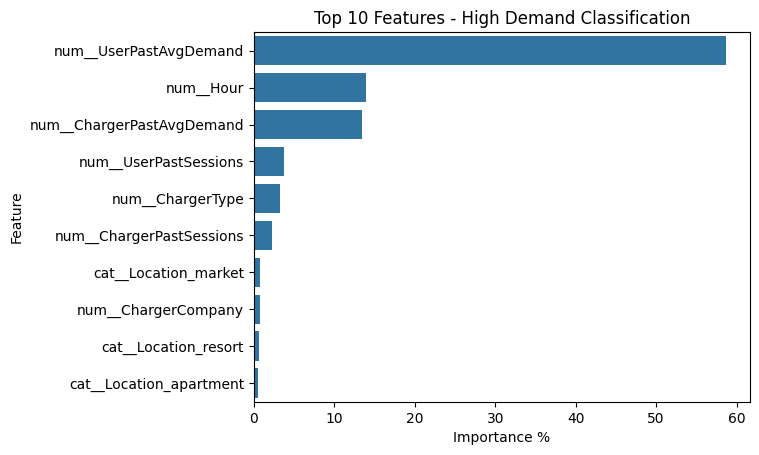

In [27]:
# Top 10 features
sns.barplot(data=importance.head(10), x='Importance %', y='Feature')
plt.title('Top 10 Features - High Demand Classification')
plt.show()

#### Step-13: SHAP

In [28]:
# SHAP on a 2000-row test sample (same as regression)
X_sample= X_test.sample(2000, random_state=42)
X_sample_df= pd.DataFrame(best_model.named_steps['preprocess'].transform(X_sample), columns=feature_names)
explainer= shap.TreeExplainer(lgbm_model)
shap_values= explainer.shap_values(X_sample_df)
np.shape(shap_values)

c:\Users\VISHNU KASHYAP\AppData\Local\Programs\Python\Python312\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


(2000, 24)

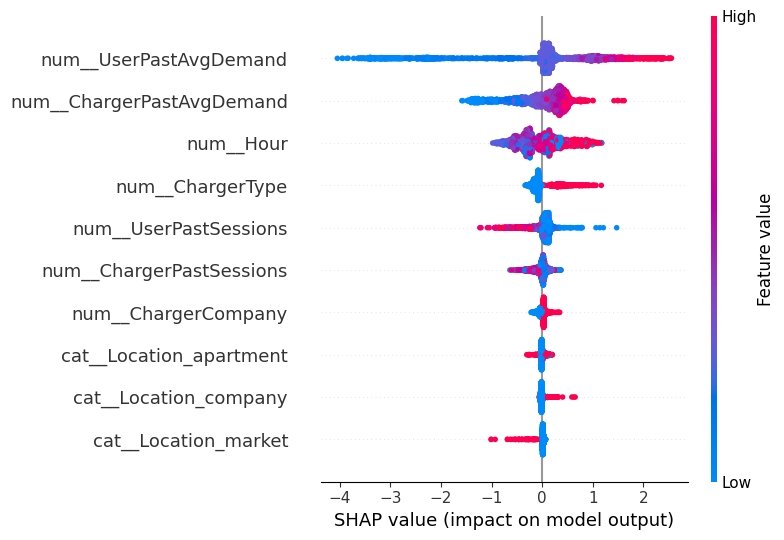

In [29]:
# Direction and size of each feature's effect on predicting High Demand
shap.summary_plot(shap_values, X_sample_df, max_display=10)

#### Step-14: LIME

In [30]:
# Explaining one test session (same row as regression)
lime_explainer= LimeTabularExplainer(best_model.named_steps['preprocess'].transform(X_train),
                                     feature_names=feature_names, class_names=['Normal', 'High'], 
                                     mode='classification', random_state=42)
row_no= 2
X_sample.iloc[row_no]

ChargerCompany                           1
ChargerType                              0
Hour                                    11
Weekday                                  4
IsWeekend                                0
IsGuest                                  0
UserPastSessions                        68
UserPastAvgDemand                43.348235
ChargerPastSessions                    375
ChargerPastAvgDemand             24.403867
Location                public institution
Name: 68806, dtype: object

In [31]:
# Actual Demand and class of that session
test.loc[X_sample.index[row_no], ['Demand', 'HighDemand']]

Demand        64.4
HighDemand       1
Name: 68806, dtype: object

In [32]:
lime_exp= lime_explainer.explain_instance(X_sample_df.iloc[row_no].values, lgbm_model.predict_proba, num_features=10)
lime_exp.predict_proba

array([0.10819154, 0.89180846])

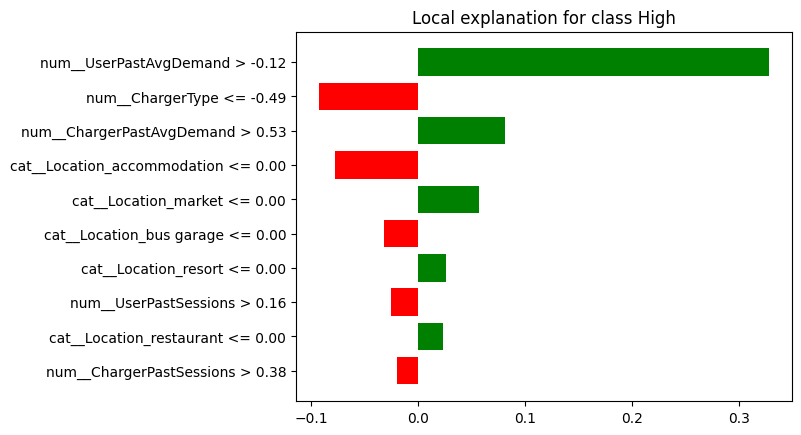

In [33]:
lime_exp.as_pyplot_figure()
plt.show()

#### Step 15: Final Observations
Summary – Classification

1. Classes are balanced, so no resampling was needed; SMOTE check gave no gain (Val AUC 0.813 vs 0.814).
2. All models beat the baseline (Dummy Val AUC 0.500); features carry real information about High Demand.
3. Random Forest (Val F1 0.742, AUC 0.817) and LightGBM (Val F1 0.741, AUC 0.814) performed best; linear models (LR, SVM) were weakest, so relationships are non-linear.
4. XGBoost and Random Forest overfit (large train–validation gap); LightGBM generalised better.
5. Tuning gave a small gain (RF CV AUC 0.819, LightGBM 0.817); LightGBM chosen as final since it is much lighter to save and faster to explain.
6. Final model (tuned LightGBM) on test: Accuracy 0.726, Precision 0.692, Recall 0.789, F1 0.737, ROC-AUC 0.806 vs baseline accuracy 0.487.
7. Recall is higher than precision: the model catches most high-demand sessions but flags some normal ones as high; for load planning this is the safer mistake.
8. Most important factors: user's past average demand, hour and charger's past average demand (Feature Importance, SHAP and LIME agree); night/late-evening sessions and fast chargers lean towards High Demand.
9. Business: plan extra capacity for evenings/nights; encourage app login; collecting planned departure time would improve predictions.